# 10 · DAG and intervention queries on reworded text
**Owner:** Jagruthi Pulumati

Phase 2. Notebook 05 again, but on the **paraphrasing** test set, where every claim is reworded:
1. turn the "X directly affects Y" claims that the pipeline calls valid into one DAG per premise
2. only **confident** DistilBERT reads (>= 0.9, notebook 07) go into the graph; the rest wait for review
3. measure edge precision and answer the same intervention queries as notebook 05
4. put the final results of the project in one table

`build_dag` and `do_effect` come from `src/c2c/bayes.py` (notebook 05).

In [1]:
# ─── IMPORTS ─────
import sys
import itertools
import warnings
warnings.filterwarnings("ignore")   # hide pgmpy deprecation messages

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

sys.path.insert(0, "../src")
from c2c.bayes import build_dag, do_effect

In [2]:
# ─── LOAD DATA ─────
predictions = pd.read_csv("../data/processed/pipeline_predictions.csv")
graphs = pd.read_csv("../data/processed/premise_graphs.csv").fillna("")
graphs = graphs[graphs["split"] == "test"]

paraphrasing = predictions[predictions["test_set"] == "paraphrasing"]
paraphrasing[["hypothesis", "relation_bert", "bert_confidence", "pred_bert", "label"]].head()

,hypothesis,relation_bert,bert_confidence,pred_bert,label
1162,A directly affects B.,direct_cause,0.986944,0,0
1163,A influences B through some mediator(s).,indirect_cause,0.956133,0,0
1164,B directly affects A.,direct_cause,0.987236,0,0
1165,B influences A through some mediator(s).,indirect_cause,0.959865,0,0
1166,A and B together cause some other variable(s).,collider,0.872200,0,0


In [3]:
# ─── STEP 1: CANDIDATE EDGES ─────
# true edges: "X directly affects Y" claims with label 1
# "A directly affects B" appears twice (as a parent and as a child claim), so we count each edge once
direct = paraphrasing[paraphrasing["relation_true"] == "direct_cause"]
true_edges = direct[direct["label"] == 1].drop_duplicates(["premise_id", "x", "y"])
print("true edges:", len(true_edges))

# regex reader: it cannot read "directly affects", so it finds no edges
regex_edges = paraphrasing[(paraphrasing["relation_regex"] == "direct_cause") & (paraphrasing["pred_regex"] == 1)]
print("regex edge claims:", len(regex_edges))

# DistilBERT reader: read as a direct cause, valid by the graph, and confident
bert_edges = paraphrasing[(paraphrasing["relation_bert"] == "direct_cause") & (paraphrasing["pred_bert"] == 1)]
confident_edges = bert_edges[bert_edges["bert_confidence"] >= 0.9].sort_values("bert_confidence", ascending=False).copy()
print("DistilBERT edge claims:", len(bert_edges), " confident:", len(confident_edges), " sent for review:", len(bert_edges) - len(confident_edges))

true edges: 65
regex edge claims: 0
DistilBERT edge claims: 138  confident: 138  sent for review: 0


In [4]:
# ─── STEP 2: BUILD THE DAGS ─────
# build_dag skips self-loops, unknown variables and edges that would make a cycle
regex_dags = {}
bert_dags = {}
for premise_id, variables in zip(graphs["premise_id"], graphs["variables"]):
    regex_dags[premise_id] = build_dag(variables.split(", "), regex_edges[regex_edges["premise_id"] == premise_id])
    bert_dags[premise_id] = build_dag(variables.split(", "), confident_edges[confident_edges["premise_id"] == premise_id])

print(len(bert_dags), "graphs, all DAGs:", all(nx.is_directed_acyclic_graph(dag) for dag in bert_dags.values()))

21 graphs, all DAGs: True


Every edge claim was read with confidence >= 0.9, so none had to wait for review. The regex reader cannot read
"directly affects", so all its graphs are empty.

In [5]:
# ─── STEP 3: EDGE PRECISION ─────
# the same as notebook 05: keep the edge claims that made it into the DAG, then check their labels
confident_edges["kept"] = confident_edges.apply(lambda r: bert_dags[r["premise_id"]].has_edge(r["x"], r["y"]), axis=1)
kept = confident_edges[confident_edges["kept"]].drop_duplicates(["premise_id", "x", "y"])   # each edge once

edge_precision = kept["label"].mean()
edge_recall = kept["label"].sum() / len(true_edges)
print("edges drawn:", len(kept), " correct:", kept["label"].sum(), " true edges:", len(true_edges))
print("edge precision:", round(edge_precision, 3), " edge recall:", round(edge_recall, 3))

edges drawn: 73  correct: 65  true edges: 65
edge precision: 0.89  edge recall: 1.0


From the reworded text we get exactly the Phase 1 graphs: edge precision 0.89 (65 of 73) and recall 1.00. The 8
extra edges are the ones PC supports but the dataset labels as not valid (notebook 02).

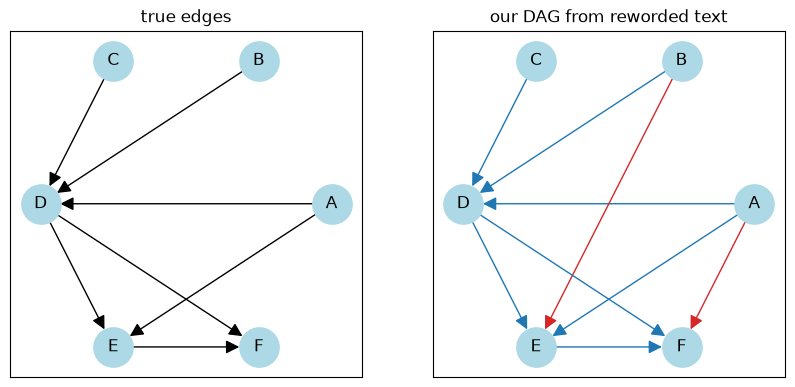

In [6]:
# one DAG from the reworded text next to the true edges (red = an edge we drew that is not true)
premise_id = kept["premise_id"].value_counts().idxmax()   # the premise with the most edges
premise_true_edges = true_edges[true_edges["premise_id"] == premise_id]

true_dag = nx.DiGraph()
true_dag.add_nodes_from(bert_dags[premise_id].nodes)
true_dag.add_edges_from(zip(premise_true_edges["x"], premise_true_edges["y"]))

our_dag = bert_dags[premise_id]
pos = nx.circular_layout(sorted(our_dag.nodes))
colors = ["tab:blue" if true_dag.has_edge(x, y) else "tab:red" for x, y in our_dag.edges]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
nx.draw_networkx(true_dag, pos, ax=axes[0], node_color="lightblue", node_size=800, arrowsize=20)
axes[0].set_title("true edges")
nx.draw_networkx(our_dag, pos, ax=axes[1], node_color="lightblue", node_size=800, arrowsize=20, edge_color=colors)
axes[1].set_title("our DAG from reworded text")
plt.savefig("../report/figures/dag_reworded.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# ─── STEP 4: INTERVENTION QUERIES ─────
# the same 5 premises as notebook 05, where PC knows the full graph, so the true answers are known
known = graphs[(graphs["mec_size"] == 1) & (graphs["directed_edges"] != "")]


def fit(edges, nodes, data):
    model = DiscreteBayesianNetwork(list(edges))
    model.add_nodes_from(nodes)
    model.fit(data, estimator=DiscreteBayesianEstimator())
    return model


rows = []
for premise_id, variables, directed_edges in zip(known["premise_id"], known["variables"], known["directed_edges"]):
    nodes = variables.split(", ")
    true_edges_pc = [tuple(e.split("->")) for e in directed_edges.split(";")]

    # true network with random probabilities (seed = premise id), and 5,000 rows simulated from it
    truth = DiscreteBayesianNetwork(true_edges_pc)
    truth.add_nodes_from(nodes)
    truth.get_random_cpds(n_states=2, inplace=True, seed=premise_id)
    sim = truth.simulate(5000, seed=premise_id, show_progress=False)

    # the DAG from the DistilBERT reader and the one from the regex reader, fitted on the same data
    ours = fit(bert_dags[premise_id].edges, nodes, sim)
    regex = fit(regex_dags[premise_id].edges, nodes, sim)

    for cause, effect in itertools.permutations(nodes, 2):
        rows.append({"premise": premise_id, "query": f"do({cause}) on {effect}",
                     "true effect": do_effect(truth, cause, effect),
                     "DistilBERT graph": do_effect(ours, cause, effect),
                     "regex graph": do_effect(regex, cause, effect),
                     "true path": effect in nx.descendants(nx.DiGraph(true_edges_pc), cause),
                     "DistilBERT path": effect in nx.descendants(bert_dags[premise_id], cause),
                     "regex path": effect in nx.descendants(regex_dags[premise_id], cause)})

queries = pd.DataFrame(rows)
print(len(queries), "queries on", queries["premise"].nunique(), "premises,", queries["true path"].sum(), "with a real effect")

96 queries on 5 premises, 32 with a real effect


In [8]:
# a query matches if the graph gets BOTH right: whether there is an effect, and its size within 0.05 (notebook 05)
def matches(graph_effect, graph_has_path):
    same_answer = graph_has_path == queries["true path"]
    return same_answer & ((queries["true effect"] - graph_effect).abs() <= 0.05)


ours_ok = matches(queries["DistilBERT graph"], queries["DistilBERT path"])
regex_ok = matches(queries["regex graph"], queries["regex path"])
pd.DataFrame({
    "all queries": [f"{ours_ok.sum()} / {len(queries)}", f"{regex_ok.sum()} / {len(queries)}"],
    "queries with a real effect": [f"{ours_ok[queries['true path']].sum()} / {queries['true path'].sum()}",
                                   f"{regex_ok[queries['true path']].sum()} / {queries['true path'].sum()}"],
}, index=["DistilBERT reader", "regex reader (Phase 1)"])

,all queries,queries with a real effect
DistilBERT reader,92 / 96,28 / 32
regex reader (Phase 1),64 / 96,0 / 32


On reworded text the Phase 1 regex finds no edges, so its graph is empty and it misses all 32 real effects. The
DistilBERT reader rebuilds the graphs, so the Bayesian network answers 28 of 32 real effects correctly, the same
as notebook 05 on the original text.

In [9]:
# ─── STEP 5: FINAL RESULTS ─────
# test F1 of every method on every test set (the predictions come from notebook 09)
original = predictions[predictions["test_set"] == "original"]
reworded = predictions[predictions["test_set"] == "paraphrasing"]
renamed = predictions[predictions["test_set"] == "refactorization"]

pd.DataFrame({
    "original": [f1_score(original["label"], original["pred_regex"]), f1_score(original["label"], original["pred_tfidf"]),
                 f1_score(original["label"], original["pred_bert"]), f1_score(original["label"], original["e2e_pred"])],
    "reworded": [f1_score(reworded["label"], reworded["pred_regex"]), f1_score(reworded["label"], reworded["pred_tfidf"]),
                 f1_score(reworded["label"], reworded["pred_bert"]), f1_score(reworded["label"], reworded["e2e_pred"])],
    "renamed": [f1_score(renamed["label"], renamed["pred_regex"]), f1_score(renamed["label"], renamed["pred_tfidf"]),
                f1_score(renamed["label"], renamed["pred_bert"]), f1_score(renamed["label"], renamed["e2e_pred"])],
}, index=["regex + PC (Phase 1)", "TF-IDF reader + PC", "DistilBERT reader + PC", "End-to-end DistilBERT"]).round(3)

,original,reworded,renamed
regex + PC (Phase 1),0.952,0.000,0.948
TF-IDF reader + PC,0.952,0.536,0.948
DistilBERT reader + PC,0.952,0.948,0.948
End-to-end DistilBERT,0.528,0.388,0.294


**Conclusion.** Language fluency alone is not causal reasoning: the end-to-end DistilBERT reaches only 0.53 F1 on
the original test and falls to 0.39 and 0.29 on reworded and renamed text. Splitting the job works: DistilBERT
reads the claim, a fixed rule renames the variables, and the PC graph decides. This pipeline keeps 0.95 F1 on all
three test sets, and its DAGs still answer the intervention queries.